# Pulso — Fase 4 (Ir Além 1): Ética e Governança em Visão Computacional
**Projeto:** Pulso — Inteligência Cardiológica com Consciência de Dados (CardioIA)  
**Fase 4:** Coração em Imagens — Assistente Cardiológico Virtual com Visão Computacional  
**Autor:** Richard Schmitz | RM 567951  
**Disciplina:** Inteligência Artificial — FIAP | Turma 2TIAOR-2026  

---

## Objetivo

Este notebook implementa o **Ir Além 1** da Fase 4: analisar os limites do dataset e medir diferenças de desempenho entre grupos nos modelos do Notebook 2, conforme o enunciado, que pede para **identificar limitações do dataset** (desbalanceamento, representatividade) e **aplicar métricas de fairness**, discutindo as implicações éticas.

O eixo do projeto Pulso é o **viés de gênero em cardiologia**, e a Fase 2 já havia testado esse viés em dados de texto. Aqui a pergunta é a mesma, mas para imagens: o modelo erra de forma diferente para mulheres e para homens? O grupo principal é, portanto, o **sexo** registrado no dataset.

## O que este notebook faz

| Parte | Conteúdo |
|---|---|
| A | Limitações do dataset: sexo, idade, projeção da radiografia (AP ou PA), desbalanceamento e exclusões |
| B | Métricas de fairness por sexo no teste (CNN do zero e ResNet50), com intervalo de confiança por bootstrap de pacientes |
| C | Faixas etárias e projeção (AP/PA). Verifica se o modelo sinaliza mais um tipo de radiografia, hipótese levantada pelo Grad-CAM do Notebook 3 |
| D | Experimento de mitigação: limiares por sexo, escolhidos na validação |
| E | Ficha do modelo (JSON e Markdown), com o contrato de uso, o desempenho e as limitações, para o restante do projeto reaproveitar |

## Decisões e justificativas

| Decisão | Escolha | Por quê |
|---|---|---|
| Grupo sensível principal | Sexo (`Patient Gender`: M ou F) | É o eixo do projeto e está no dataset. Só há duas categorias, então outras identidades não podem ser avaliadas |
| Onde medir | Só no conjunto de teste, com o limiar escolhido na validação | Mesma regra do Notebook 2. Também atende à pendência da Fase 2 de avaliar subgrupos apenas no teste |
| Incerteza | Bootstrap de 1000 repetições reamostrando **pacientes**, IC de 95% | O teste tem 19 positivos (9 F e 10 M). Sem intervalo, qualquer diferença pareceria resultado |
| Leitura das diferenças | Se o IC inclui zero, a diferença **não está demonstrada** | Evita tirar conclusão de amostra pequena |
| Mitigação | Limiares por sexo que igualam a taxa de sinalização na validação | Os positivos na validação por sexo são poucos para igualar o recall. A taxa de sinalização usa todas as imagens |
| Saída para as próximas fases | `ficha_do_modelo.json` e `.md` | Uma fonte única de números e limitações, em vez de cada fase repetir valores à mão |

## Aviso

Projeto acadêmico. Nada aqui produz diagnóstico nem deve apoiar decisão clínica.

In [1]:
import os
import sys
import json
import shutil
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import scipy
from scipy.stats import fisher_exact
from sklearn.metrics import roc_auc_score
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings("ignore")

SEED = 42
N_REP = 1000   # repeticoes do bootstrap
try:
    import google.colab  # noqa: F401
    COLAB = True
except ImportError:
    COLAB = False
print("Ambiente:", "Google Colab" if COLAB else "Local")

Ambiente: Google Colab


## 1. Pastas e arquivos de entrada

Este notebook **não treina nada**. Ele lê as previsões que o Notebook 2 salvou (`pred_val_*.csv` e `pred_teste_*.csv`), as partições do Notebook 1 (`splits.csv`) e o CSV original do dataset, de onde vem a projeção da radiografia (`View Position`), que o Notebook 1 não guardou. Se algum arquivo faltar, a execução para e avisa.

In [2]:
BASE = Path("/content/pulso_f4") if COLAB else Path("./pulso_f4")
if COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE = Path("/content/drive/MyDrive/Pulso_F4")
    except Exception as erro:
        print("Drive nao montado, usando o disco temporario:", erro)
SAIDA = BASE / "saida"
DATA = BASE / "data"
MODELOS = {"cnn_simples": "CNN simples (do zero)", "resnet50": "ResNet50 (Transfer Learning)"}
necessarios = ["splits.csv", "metricas_nb2.json"] + ["pred_%s_%s.csv" % (t, m) for t in ["val", "teste"] for m in MODELOS]
faltando = [n for n in necessarios if not (SAIDA / n).exists()]
if faltando:
    raise FileNotFoundError("Arquivos nao encontrados em %s: %s. Execute os Notebooks 1 e 2 antes." % (SAIDA, faltando))

def achar_csv_rotulos(pasta):
    for csv in sorted(pasta.rglob("*.csv")):
        colunas = pd.read_csv(csv, nrows=0).columns
        if any("finding" in c.lower() for c in colunas):
            return csv
    raise FileNotFoundError("CSV original do dataset nao encontrado em " + str(pasta))

csv_original = achar_csv_rotulos(DATA)
print("CSV original:", csv_original.relative_to(DATA))
print("Saida:", SAIDA)

Mounted at /content/drive
CSV original: sample/sample_labels.csv
Saida: /content/drive/MyDrive/Pulso_F4/saida


## 2. Montagem das tabelas de análise

Cada imagem recebe sexo, idade, projeção e partição. Antes de qualquer cálculo, o notebook confere por `assert` que os rótulos das previsões batem com o `splits.csv`, que o sexo do `splits.csv` bate com o do CSV original e que as previsões vêm da partição certa. Qualquer divergência interrompe a execução.

In [3]:
original = pd.read_csv(csv_original)
original = original.rename(columns={"Image Index": "imagem", "View Position": "posicao", "Patient Gender": "sexo_original", "Finding Labels": "achados"})
splits = pd.read_csv(SAIDA / "splits.csv")
meta = splits.merge(original[["imagem", "posicao", "sexo_original"]], on="imagem", how="left", validate="one_to_one")
assert meta["posicao"].notna().all(), "Imagens do splits.csv sem projecao no CSV original"
assert (meta["sexo"] == meta["sexo_original"]).all(), "Sexo do splits.csv difere do CSV original"
meta = meta.drop(columns=["sexo_original"])
meta["faixa_etaria"] = pd.cut(meta["idade"], bins=[0, 40, 60, 200], right=False, labels=["<40", "40-59", "60+"])
print("Registros do experimento:", len(meta), "| projecoes:", meta["posicao"].value_counts().to_dict())

metricas_nb2 = json.loads((SAIDA / "metricas_nb2.json").read_text(encoding="utf-8"))
LIMIAR = {m: float(metricas_nb2["modelos"][m]["limiar"]) for m in MODELOS}

def carregar_previsoes(tipo, modelo):
    d = pd.read_csv(SAIDA / ("pred_%s_%s.csv" % (tipo, modelo)))
    d = d.merge(meta, on="imagem", how="left", validate="one_to_one")
    assert d["sexo"].notna().all(), "Imagens das previsoes ausentes no splits.csv"
    assert (d["y"] == d["rotulo"]).all(), "Rotulo das previsoes difere do splits.csv"
    esperado = "teste" if tipo == "teste" else "validacao"
    assert (d["particao"] == esperado).all(), "Particao inesperada em pred_%s_%s.csv" % (tipo, modelo)
    return d

TESTE = {m: carregar_previsoes("teste", m) for m in MODELOS}
VAL = {m: carregar_previsoes("val", m) for m in MODELOS}
t = TESTE["resnet50"]
print("Teste: %d imagens, %d positivos, %d pacientes" % (len(t), int(t["y"].sum()), t["paciente"].nunique()))
print("Limiares:", {m: LIMIAR[m] for m in MODELOS})

Registros do experimento: 3185 | projecoes: {'PA': 2064, 'AP': 1121}
Teste: 446 imagens, 19 positivos, 395 pacientes
Limiares: {'cnn_simples': 0.79, 'resnet50': 0.35}


### Leitura da montagem

O experimento tem 3.185 imagens, das quais 446 são o teste, com 19 positivos. A projeção está disponível para todas as imagens: 2.064 em PA e 1.121 em AP. Os limiares vêm do `metricas_nb2.json`: 0,79 para a CNN e 0,35 para a ResNet50.

## Parte A. Limitações do dataset

Três perguntas orientam esta parte: o problema é desbalanceado? A amostra representa homens e mulheres, idades e tipos de radiografia de forma parecida em cada classe? Quantos positivos cada grupo tem, ou seja, **quanta evidência existe para cada comparação**? As tabelas usam o experimento inteiro, e não só o teste, porque descrevem o **dataset**, e não o desempenho de um modelo.

Amostra original completa (antes das exclusoes): 5606 imagens
  sexo: {'M': 3134, 'F': 2472} | projecao: {'PA': 3393, 'AP': 2213}
Excluidas por terem outras doencas e nao cardiomegalia: 2421 de 5606
Experimento: 3185 imagens, 141 positivos (4.43%)

Experimento inteiro por sexo:


,imagens,positivos,pacientes,prevalencia_%
sexo,,,,
F,1416,73,1239,5.16
M,1769,68,1523,3.84



Experimento inteiro por faixa_etaria:


,imagens,positivos,pacientes,prevalencia_%
faixa_etaria,,,,
<40,1127,48,972,4.26
40-59,1402,55,1232,3.92
60+,655,38,571,5.80



Experimento inteiro por posicao:


,imagens,positivos,pacientes,prevalencia_%
posicao,,,,
PA,2064,77,1944,3.73
AP,1121,64,935,5.71



Prevalencia de cardiomegalia por sexo no experimento inteiro: F 5.16% | M 3.84% (teste exato de Fisher, p = 0.083)

Teste (onde as metricas sao calculadas), por sexo:


,imagens,positivos,pacientes,prevalencia_%
sexo,,,,
F,194,9,173,4.64
M,252,10,222,3.97


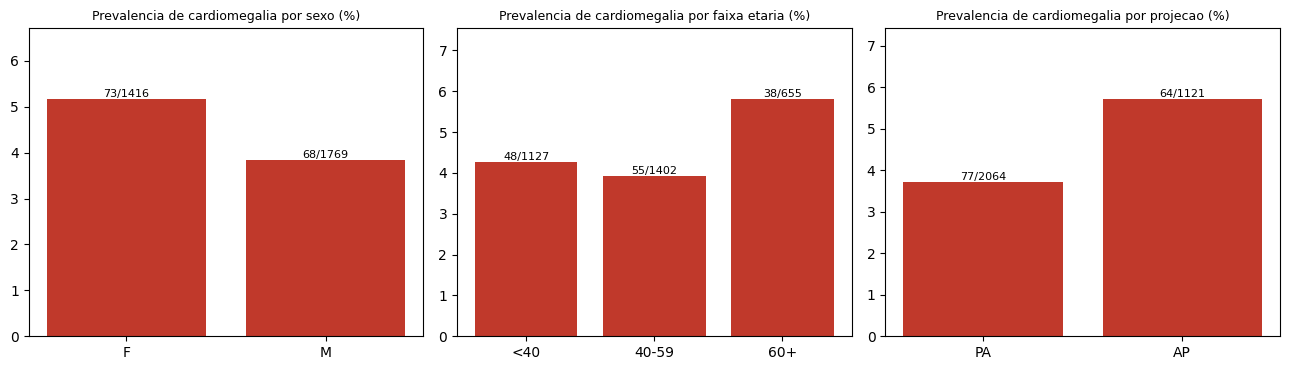

In [4]:
def tabela_grupo(df, col, ordem=None):
    g = df.groupby(col, observed=True).agg(imagens=("y", "size"), positivos=("y", "sum"), pacientes=("paciente", "nunique"))
    g["prevalencia_%"] = (100 * g["positivos"] / g["imagens"]).round(2)
    return g.loc[ordem] if ordem else g

print("Amostra original completa (antes das exclusoes): %d imagens" % len(original))
print("  sexo:", original["sexo_original"].value_counts().to_dict(), "| projecao:", original["posicao"].value_counts().to_dict())
print("Excluidas por terem outras doencas e nao cardiomegalia: %d de %d" % (len(original) - len(meta), len(original)))
print("Experimento: %d imagens, %d positivos (%.2f%%)" % (len(meta), meta["rotulo"].sum(), 100 * meta["rotulo"].mean()))
meta_y = meta.rename(columns={"rotulo": "y"})
for col, ordem in [("sexo", ["F", "M"]), ("faixa_etaria", ["<40", "40-59", "60+"]), ("posicao", ["PA", "AP"])]:
    print()
    print("Experimento inteiro por %s:" % col)
    display(tabela_grupo(meta_y, col, ordem))

tab = pd.crosstab(meta["sexo"], meta["rotulo"]).loc[["F", "M"]]
_, p_fisher = fisher_exact(tab.values[:, [1, 0]])
print()
print("Prevalencia de cardiomegalia por sexo no experimento inteiro: F %.2f%% | M %.2f%% (teste exato de Fisher, p = %.3f)" % (
    100 * tab.loc["F", 1] / tab.loc["F"].sum(), 100 * tab.loc["M", 1] / tab.loc["M"].sum(), p_fisher))
print()
print("Teste (onde as metricas sao calculadas), por sexo:")
display(tabela_grupo(t, "sexo", ["F", "M"]))

fig, eixos = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (col, ordem, nome) in zip(eixos, [("sexo", ["F", "M"], "sexo"), ("faixa_etaria", ["<40", "40-59", "60+"], "faixa etaria"), ("posicao", ["PA", "AP"], "projecao")]):
    g = tabela_grupo(meta_y, col, ordem)
    ax.bar(range(len(g)), g["prevalencia_%"], color="#c0392b")
    for i, (prev, pos, n) in enumerate(zip(g["prevalencia_%"], g["positivos"], g["imagens"])):
        ax.text(i, prev, "%d/%d" % (pos, n), ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index)
    ax.set_title("Prevalencia de cardiomegalia por %s (%%)" % nome, fontsize=9)
    ax.set_ylim(0, max(g["prevalencia_%"].max() * 1.3, 1))
plt.tight_layout(); plt.savefig(SAIDA / "nb4_dataset_prevalencia.png", dpi=130); plt.show()

### Leitura das limitações do dataset

- **Desbalanceamento:** 141 positivos em 3.185 imagens (4,43%). Dos 5.606 registros originais, 2.421 foram excluídos por terem outras doenças.
- **Sexo:** a amostra original tem 2.472 mulheres e 3.134 homens (44,1% de mulheres). No experimento, as mulheres têm 73 positivos em 1.416 imagens (5,16%) e os homens 68 em 1.769 (3,84%). A diferença de prevalência não é significativa a 5% (teste exato de Fisher, p = 0,083).
- **Projeção:** a prevalência é maior em AP (5,71%, 64 de 1.121) do que em PA (3,73%, 77 de 2.064). A projeção, portanto, carrega informação sobre o rótulo no próprio dataset.
- **Idade:** a faixa de 60 anos ou mais apresenta a maior prevalência (5,80%, 38 de 655).
- **Positivos por grupo no teste:** 9 mulheres e 10 homens. Qualquer comparação entre os sexos tem evidências fracas.

## Parte B. Métricas de fairness por sexo

Cada métrica de fairness traduz uma ideia diferente de "tratar os grupos de forma justa", calculada por grupo (F e M) com o limiar de cada modelo:

- **Taxa de sinalização** (paridade demográfica): fração de imagens sinalizadas.
- **Recall** (igualdade de oportunidade): entre as imagens com cardiomegalia no laudo, fração sinalizada.
- **Taxa de falsos positivos**: entre as imagens sem achados, fração sinalizada. Recall e taxa de falsos positivos iguais nos dois grupos formam os *odds equalizados*.
- **Precisão** (paridade preditiva): entre as sinalizadas, fração com cardiomegalia no laudo.
- **AUC-ROC**: capacidade de ordenar os casos, independente do limiar.

Quando a prevalência difere entre os grupos, **não é possível igualar todas essas métricas ao mesmo tempo** (Chouldechova, 2017; Kleinberg et al., 2016). Por isso o notebook mostra todas, em vez de escolher uma.

A tabela traz a diferença **F menos M** com IC de 95% por bootstrap de pacientes. Se o IC inclui zero, a diferença não está demonstrada por este teste.

In [5]:
METRICAS = ["selecao", "recall", "fpr", "precisao", "auc_roc"]
NOMES = {"selecao": "taxa de sinalizacao", "recall": "recall", "fpr": "falsos positivos", "precisao": "precisao", "auc_roc": "AUC-ROC"}

def metricas_grupo(y, p, pred):
    """Metricas de um grupo. 'pred' e o vetor booleano de sinalizacao (p >= limiar do grupo)."""
    y = np.asarray(y).astype(int); pred = np.asarray(pred).astype(bool)
    pos = int(y.sum()); neg = int(len(y) - pos)
    tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum())
    return {
        "n": int(len(y)), "positivos": pos, "tp": tp, "fp": fp,
        "selecao": float(pred.mean()) if len(y) else np.nan,
        "recall": tp / pos if pos else np.nan,
        "fpr": fp / neg if neg else np.nan,
        "precisao": tp / int(pred.sum()) if pred.sum() else np.nan,
        "auc_roc": float(roc_auc_score(y, p)) if pos and neg else np.nan,
    }

def leitura(lo, hi):
    if not (np.isfinite(lo) and np.isfinite(hi)):
        return "indefinido"
    return "IC inclui 0: diferenca nao demonstrada" if lo <= 0 <= hi else "IC exclui 0: diferenca observada nesta amostra"

def comparar_grupos(df, limiar_por_grupo, g1="F", g2="M", col="sexo", n_rep=N_REP, seed=SEED):
    """Diferenca (g1 - g2) de cada metrica, com IC95% por bootstrap reamostrando pacientes."""
    y = df["y"].values.astype(int); p = df["prob"].values; g = df[col].values
    limiar_linha = np.array([limiar_por_grupo[x] for x in g])
    pred = p >= limiar_linha
    obs = {x: metricas_grupo(y[g == x], p[g == x], pred[g == x]) for x in (g1, g2)}
    grupos_pac = [i.index.values for _, i in pd.DataFrame({"pac": df["paciente"].values}).groupby("pac")]
    rng = np.random.default_rng(seed)
    dif = {m: [] for m in METRICAS}
    for _ in range(n_rep):
        idx = np.concatenate([grupos_pac[k] for k in rng.integers(0, len(grupos_pac), len(grupos_pac))])
        gi = g[idx]
        a, b = idx[gi == g1], idx[gi == g2]
        ma, mb = metricas_grupo(y[a], p[a], pred[a]), metricas_grupo(y[b], p[b], pred[b])
        for m in METRICAS:
            dif[m].append(ma[m] - mb[m])
    linhas = []
    for m in METRICAS:
        v = np.array(dif[m], dtype=float); v = v[np.isfinite(v)]
        lo, hi = (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) if len(v) else (np.nan, np.nan)
        linhas.append({"metrica": NOMES[m], g1: obs[g1][m], g2: obs[g2][m], "dif_%s_menos_%s" % (g1, g2): obs[g1][m] - obs[g2][m],
                       "ic95_inf": lo, "ic95_sup": hi, "reps_validas": int(len(v)), "leitura": leitura(lo, hi)})
    return pd.DataFrame(linhas).set_index("metrica"), obs

FAIRNESS = {}
for m, rotulo in MODELOS.items():
    tabela, obs = comparar_grupos(TESTE[m], {"F": LIMIAR[m], "M": LIMIAR[m]})
    FAIRNESS[m] = {"tabela": tabela, "obs": obs}
    print("=" * 78)
    print("%s | limiar %.2f" % (rotulo, LIMIAR[m]))
    print("Teste: F = %d imagens (%d positivos) | M = %d imagens (%d positivos)" % (obs["F"]["n"], obs["F"]["positivos"], obs["M"]["n"], obs["M"]["positivos"]))
    print("Sinalizadas corretamente (tp) F %d/%d | M %d/%d" % (obs["F"]["tp"], obs["F"]["positivos"], obs["M"]["tp"], obs["M"]["positivos"]))
    pd.set_option("display.width", 220); pd.set_option("display.max_columns", 20)
    display(tabela.round(3))
    razao = obs["F"]["selecao"] / obs["M"]["selecao"] if obs["M"]["selecao"] else np.nan
    print("Razao de sinalizacao F/M: %.2f (1,00 = mesma taxa). Prevalencia no teste difere entre os grupos, entao taxas iguais nao sao esperadas." % razao)
    tabela.to_csv(SAIDA / ("nb4_fairness_sexo_%s.csv" % m))

CNN simples (do zero) | limiar 0.79
Teste: F = 194 imagens (9 positivos) | M = 252 imagens (10 positivos)
Sinalizadas corretamente (tp) F 1/9 | M 5/10


,F,M,dif_F_menos_M,ic95_inf,ic95_sup,reps_validas,leitura
metrica,,,,,,,
taxa de sinalizacao,0.149,0.087,0.062,-0.000,0.130,1000,IC inclui 0: diferenca nao demonstrada
recall,0.111,0.500,-0.389,-0.723,0.200,995,IC inclui 0: diferenca nao demonstrada
falsos positivos,0.151,0.070,0.081,0.023,0.142,1000,IC exclui 0: diferenca observada nesta amostra
precisao,0.034,0.227,-0.193,-0.438,0.056,1000,IC inclui 0: diferenca nao demonstrada
AUC-ROC,0.482,0.809,-0.327,-0.496,-0.099,995,IC exclui 0: diferenca observada nesta amostra


Razao de sinalizacao F/M: 1.71 (1,00 = mesma taxa). Prevalencia no teste difere entre os grupos, entao taxas iguais nao sao esperadas.
ResNet50 (Transfer Learning) | limiar 0.35
Teste: F = 194 imagens (9 positivos) | M = 252 imagens (10 positivos)
Sinalizadas corretamente (tp) F 8/9 | M 9/10


,F,M,dif_F_menos_M,ic95_inf,ic95_sup,reps_validas,leitura
metrica,,,,,,,
taxa de sinalizacao,0.325,0.373,-0.048,-0.142,0.046,1000,IC inclui 0: diferenca nao demonstrada
recall,0.889,0.900,-0.011,-0.301,0.573,995,IC inclui 0: diferenca nao demonstrada
falsos positivos,0.297,0.351,-0.054,-0.145,0.032,1000,IC inclui 0: diferenca nao demonstrada
precisao,0.127,0.096,0.031,-0.094,0.153,1000,IC inclui 0: diferenca nao demonstrada
AUC-ROC,0.843,0.855,-0.013,-0.135,0.243,995,IC inclui 0: diferenca nao demonstrada


Razao de sinalizacao F/M: 0.87 (1,00 = mesma taxa). Prevalencia no teste difere entre os grupos, entao taxas iguais nao sao esperadas.


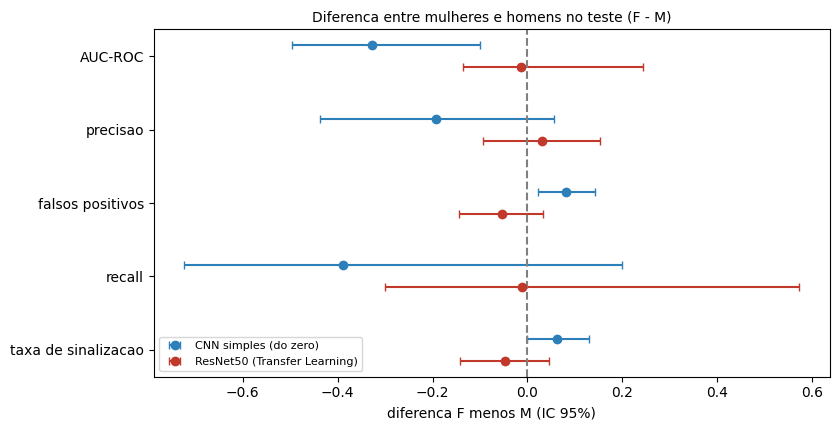

In [6]:
def grafico_floresta(tabelas, caminho, titulo):
    fig, ax = plt.subplots(figsize=(8.5, 4.4))
    cores = {"cnn_simples": "#2c7fb8", "resnet50": "#c0392b"}
    for k, (m, tab) in enumerate(tabelas.items()):
        col = [c for c in tab.columns if c.startswith("dif_")][0]
        for i, nome in enumerate(tab.index):
            d, lo, hi = tab.loc[nome, col], tab.loc[nome, "ic95_inf"], tab.loc[nome, "ic95_sup"]
            if not np.isfinite(d):
                continue
            y = i + (0.15 if k == 0 else -0.15)
            ax.errorbar(d, y, xerr=[[d - lo], [hi - d]], fmt="o", color=cores[m], capsize=3, label=MODELOS[m] if i == 0 else None)
    ax.axvline(0, color="gray", ls="--")
    ax.set_yticks(range(len(tabelas["resnet50"].index))); ax.set_yticklabels(tabelas["resnet50"].index)
    ax.set_xlabel("diferenca F menos M (IC 95%)"); ax.set_title(titulo, fontsize=10); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(caminho, dpi=130); plt.show()

grafico_floresta({m: FAIRNESS[m]["tabela"] for m in MODELOS}, SAIDA / "nb4_fairness_sexo.png", "Diferenca entre mulheres e homens no teste (F - M)")

### Leitura dos resultados por sexo

**ResNet50** (limiar 0,35; positivos acertados: F 8/9, M 9/10):

| Métrica | F | M | Diferença F - M | IC 95% | Leitura |
|---|---|---|---|---|---|
| taxa de sinalização | 0,325 | 0,373 | -0,048 | [-0,142 a 0,046] | diferença não demonstrada |
| recall | 0,889 | 0,900 | -0,011 | [-0,301 a 0,573] | diferença não demonstrada |
| falsos positivos | 0,297 | 0,351 | -0,054 | [-0,145 a 0,032] | diferença não demonstrada |
| precisão | 0,127 | 0,096 | 0,031 | [-0,094 a 0,153] | diferença não demonstrada |
| AUC-ROC | 0,843 | 0,855 | -0,013 | [-0,135 a 0,243] | diferença não demonstrada |

Nenhuma diferença demonstrada. Isso não prova igualdade: o recall é 0,889 para mulheres e 0,900 para homens, mas o IC da diferença é [-0,301 a 0,573], muito largo, porque cada grupo tem cerca de 10 positivos.

**CNN simples** (limiar 0,79; positivos acertados: F 1/9, M 5/10):

| Métrica | F | M | Diferença F - M | IC 95% | Leitura |
|---|---|---|---|---|---|
| taxa de sinalização | 0,149 | 0,087 | 0,062 | [-0,000 a 0,130] | diferença não demonstrada |
| recall | 0,111 | 0,500 | -0,389 | [-0,723 a 0,200] | diferença não demonstrada |
| falsos positivos | 0,151 | 0,070 | 0,081 | [0,023 a 0,142] | diferença observada nesta amostra |
| precisão | 0,034 | 0,227 | -0,193 | [-0,438 a 0,056] | diferença não demonstrada |
| AUC-ROC | 0,482 | 0,809 | -0,327 | [-0,496 a -0,099] | diferença observada nesta amostra |

Duas das cinco métricas excluem zero. A AUC-ROC é 0,482 para mulheres e 0,809 para homens (diferença de -0,327, IC [-0,496 a -0,099]), e a taxa de falsos positivos é de 15,1% para mulheres e 7,0% para homens (diferença de 0,081, IC [0,023 a 0,142]). A AUC-ROC de 0,482 para mulheres é compatível com ordenação ao acaso, com apenas 9 positivos.

**Cuidado com múltiplas comparações.** Foram 10 comparações (5 métricas em 2 modelos), sem correção para testes múltiplos, e 2 delas excluem zero. Esses dois resultados são hipóteses a serem investigadas com mais dados, e não conclusões.

## Parte C. Faixa etária e projeção da radiografia

No Notebook 3, o Grad-CAM de um falso positivo mostrou uma radiografia portátil em AP. Isso levanta uma hipótese: o modelo pode reagir ao **tipo de radiografia** e não à cardiomegalia. Na literatura radiológica, a razão cardiotorácica só é confiável na projeção PA ([PubMed 22065900](https://pubmed.ncbi.nlm.nih.gov/22065900/); [Radiopaedia](https://radiopaedia.org/articles/cardiothoracic-ratio)), e a passagem de PA para AP amplia a silhueta cardíaca ([PubMed 2966252](https://pubmed.ncbi.nlm.nih.gov/2966252/)). Se o modelo usa essa pista, ele tende a sinalizar mais imagens AP.

**Teste:** entre as imagens **sem achados** do teste, a taxa de falsos positivos deveria ser parecida em AP e PA. A tabela mostra a taxa com intervalo de Wilson, para a ResNet50. O recall por faixa ou projeção aparece só como contagem (acertos/positivos), porque cada grupo tem poucos positivos para um intervalo útil.

In [7]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    ph = k / n; den = 1 + z ** 2 / n
    centro = (ph + z ** 2 / (2 * n)) / den
    meia = z * np.sqrt(ph * (1 - ph) / n + z ** 2 / (4 * n ** 2)) / den
    return (centro - meia, centro + meia)

def perfil(df, col, ordem, limiar):
    linhas = []
    for gname in ordem:
        s = df[df[col] == gname]
        pred = s["prob"].values >= limiar; y = s["y"].values.astype(int)
        pos = int(y.sum()); neg = int((y == 0).sum()); tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum())
        lo, hi = wilson(fp, neg)
        linhas.append({col: gname, "imagens": len(s), "positivos": pos, "acertos_positivos": "%d/%d" % (tp, pos), "negativos": neg,
                       "falsos_positivos": fp, "fpr": fp / neg if neg else np.nan, "fpr_ic95_inf": lo, "fpr_ic95_sup": hi,
                       "pontuacao_media_negativos": float(s.loc[s["y"] == 0, "prob"].mean()) if neg else np.nan})
    return pd.DataFrame(linhas).set_index(col)

tr = TESTE["resnet50"]; lim = LIMIAR["resnet50"]
print("ResNet50, limiar %.2f, conjunto de teste" % lim)
print()
print("Por projecao:")
perfil_proj = perfil(tr, "posicao", ["PA", "AP"], lim); display(perfil_proj.round(3))
ap, pa = perfil_proj.loc["AP"], perfil_proj.loc["PA"]
if ap["negativos"] and pa["negativos"]:
    _, p_proj = fisher_exact([[ap["falsos_positivos"], ap["negativos"] - ap["falsos_positivos"]], [pa["falsos_positivos"], pa["negativos"] - pa["falsos_positivos"]]])
    print("Falsos positivos entre imagens sem achados: AP %.1f%% | PA %.1f%% (Fisher, p = %.3f)" % (100 * ap["fpr"], 100 * pa["fpr"], p_proj))
print()
print("Por faixa etaria:")
perfil_idade = perfil(tr.dropna(subset=["faixa_etaria"]), "faixa_etaria", ["<40", "40-59", "60+"], lim); display(perfil_idade.round(3))
print("Imagens do teste sem idade valida:", int(tr["faixa_etaria"].isna().sum()))
perfil_proj.to_csv(SAIDA / "nb4_perfil_projecao_resnet50.csv"); perfil_idade.to_csv(SAIDA / "nb4_perfil_idade_resnet50.csv")
if len(tr[(tr["posicao"] == "AP") & (tr["y"] == 1)]) < 10:
    print("ATENCAO: poucos positivos em AP no teste. A comparacao de recall entre projecoes nao e possivel.")

ResNet50, limiar 0.35, conjunto de teste

Por projecao:


,imagens,positivos,acertos_positivos,negativos,falsos_positivos,fpr,fpr_ic95_inf,fpr_ic95_sup,pontuacao_media_negativos
posicao,,,,,,,,,
PA,306,8,6/8,298,77,0.258,0.212,0.311,0.247
AP,140,11,11/11,129,63,0.488,0.404,0.574,0.384


Falsos positivos entre imagens sem achados: AP 48.8% | PA 25.8% (Fisher, p = 0.000)

Por faixa etaria:


,imagens,positivos,acertos_positivos,negativos,falsos_positivos,fpr,fpr_ic95_inf,fpr_ic95_sup,pontuacao_media_negativos
faixa_etaria,,,,,,,,,
<40,174,7,6/7,167,48,0.287,0.224,0.360,0.26
40-59,184,6,6/6,178,60,0.337,0.272,0.409,0.30
60+,88,6,5/6,82,32,0.390,0.292,0.498,0.32


Imagens do teste sem idade valida: 0


### Leitura da projeção e da faixa etária

A ResNet50, entre as imagens **sem achados** do teste:

| Projeção | Imagens | Sem achados | Falsos positivos | Taxa de falsos positivos (IC 95% de Wilson) | Positivos acertados |
|---|---|---|---|---|---|
| PA | 306 | 298 | 77 | 25,8% [21,2% a 31,1%] | 6/8 |
| AP | 140 | 129 | 63 | 48,8% [40,4% a 57,4%] | 11/11 |

A taxa de falsos positivos é mais do que o dobro em AP (48,8% contra 25,8%; teste exato de Fisher, p < 0,001). Isso **sustenta a hipótese**: o modelo reage a características associadas à projeção AP, e não apenas à silhueta cardíaca. Há uma ressalva: a projeção AP também apresenta maior prevalência de cardiomegalia no dataset (5,71% contra 3,73%), então parte da sensibilidade pode refletir uma correlação real entre projeção e rótulo, e não foi isolado o que o modelo usa no exame AP. O recall por projeção é apenas descritivo: positivos acertados em AP: 11/11 e em PA: 6/8.

Por faixa etária (mesmo modelo, imagens sem achados):

| Faixa etária | Imagens | Sem achados | Taxa de falsos positivos (IC 95% de Wilson) | Positivos acertados |
|---|---|---|---|---|
| <40 | 174 | 167 | 28,7% [22,4% a 36,0%] | 6/7 |
| 40-59 | 184 | 178 | 33,7% [27,2% a 40,9%] | 6/6 |
| 60+ | 88 | 82 | 39,0% [29,2% a 49,8%] | 5/6 |

A taxa de falsos positivos cresce com a idade, mas os intervalos se sobrepõem: a diferença entre as faixas não está demonstrada.

## Parte D. Experimento de mitigação: limiares por sexo

Um limiar único pode sinalizar grupos em taxas diferentes. O experimento escolhe, **na validação**, um limiar para cada sexo, de modo que a taxa de sinalização de cada grupo seja igual à taxa geral do limiar original. Depois aplica esses limiares no teste, sem reajuste.

Por que essa regra e não igualar o recall? Na validação há poucos positivos, e poucos deles são homens. Estimar um limiar por recall com tão poucos casos seria instável. A taxa de sinalização usa todas as imagens da validação.

Isto é um **experimento**, não uma recomendação. Usar o sexo como entrada da decisão tem custos: o mesmo escore passa a ter significados diferentes por grupo, pode haver restrições legais e éticas em contexto clínico, e igualar a taxa de sinalização não garante igualdade de benefício entre os pacientes.

CNN simples (do zero)
Taxa geral de sinalizacao na validacao: 10.4% | limiar original 0.79
Limiares por sexo (validacao): F 0.802 | M 0.769
Positivos na validacao: F 17 | M 5 (por isso nao se iguala o recall)


,dif antes,IC antes,dif depois,IC depois
metrica,,,,
taxa de sinalizacao,0.062,"[-0.000, 0.130]",-0.004,"[-0.071, 0.061]"
recall,-0.389,"[-0.723, 0.200]",-0.389,"[-0.723, 0.200]"
falsos positivos,0.081,"[0.023, 0.142]",0.011,"[-0.048, 0.071]"
precisao,-0.193,"[-0.438, 0.056]",-0.118,"[-0.316, 0.074]"
AUC-ROC,-0.327,"[-0.496, -0.099]",-0.327,"[-0.496, -0.099]"


Casos com cardiomegalia sinalizados no teste: antes 6 | depois 6 (de 19)
Imagens sinalizadas no teste: antes 51 | depois 54 (de 446)
ResNet50 (Transfer Learning)
Taxa geral de sinalizacao na validacao: 35.5% | limiar original 0.35
Limiares por sexo (validacao): F 0.350 | M 0.350
Positivos na validacao: F 17 | M 5 (por isso nao se iguala o recall)


,dif antes,IC antes,dif depois,IC depois
metrica,,,,
taxa de sinalizacao,-0.048,"[-0.142, 0.046]",-0.048,"[-0.142, 0.046]"
recall,-0.011,"[-0.301, 0.573]",-0.011,"[-0.301, 0.573]"
falsos positivos,-0.054,"[-0.145, 0.032]",-0.054,"[-0.145, 0.032]"
precisao,0.031,"[-0.094, 0.153]",0.031,"[-0.094, 0.153]"
AUC-ROC,-0.013,"[-0.135, 0.243]",-0.013,"[-0.135, 0.243]"


Casos com cardiomegalia sinalizados no teste: antes 17 | depois 17 (de 19)
Imagens sinalizadas no teste: antes 157 | depois 157 (de 446)


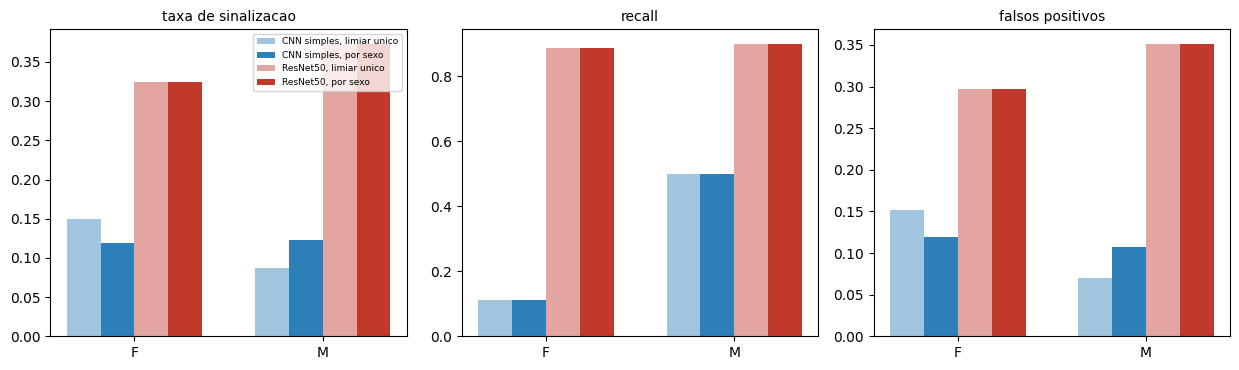

In [8]:
def limiares_por_sexo(val, limiar_global):
    taxa = float((val["prob"].values >= limiar_global).mean())
    return {g: float(np.quantile(val.loc[val["sexo"] == g, "prob"].values, 1 - taxa)) for g in ["F", "M"]}, taxa

MITIGACAO = {}
for m, rotulo in MODELOS.items():
    lim_g, taxa = limiares_por_sexo(VAL[m], LIMIAR[m])
    antes = FAIRNESS[m]["tabela"]
    depois, obs_dep = comparar_grupos(TESTE[m], lim_g)
    MITIGACAO[m] = {"limiares": lim_g, "taxa_validacao": taxa, "depois": depois, "obs_depois": obs_dep}
    print("=" * 78)
    print("%s" % rotulo)
    print("Taxa geral de sinalizacao na validacao: %.1f%% | limiar original %.2f" % (100 * taxa, LIMIAR[m]))
    print("Limiares por sexo (validacao): F %.3f | M %.3f" % (lim_g["F"], lim_g["M"]))
    print("Positivos na validacao: F %d | M %d (por isso nao se iguala o recall)" % (
        int(VAL[m].query("sexo == 'F'")["y"].sum()), int(VAL[m].query("sexo == 'M'")["y"].sum())))
    col = "dif_F_menos_M"
    comp = pd.DataFrame({
        "dif antes": antes[col], "IC antes": ["[%.3f, %.3f]" % (a, b) for a, b in zip(antes["ic95_inf"], antes["ic95_sup"])],
        "dif depois": depois[col], "IC depois": ["[%.3f, %.3f]" % (a, b) for a, b in zip(depois["ic95_inf"], depois["ic95_sup"])],
    })
    display(comp.round(3))
    tot_a = sum(FAIRNESS[m]["obs"][g]["tp"] for g in "FM"); tot_d = sum(obs_dep[g]["tp"] for g in "FM")
    sel_a = sum(FAIRNESS[m]["obs"][g]["selecao"] * FAIRNESS[m]["obs"][g]["n"] for g in "FM"); sel_d = sum(obs_dep[g]["selecao"] * obs_dep[g]["n"] for g in "FM")
    print("Casos com cardiomegalia sinalizados no teste: antes %d | depois %d (de %d)" % (tot_a, tot_d, FAIRNESS[m]["obs"]["F"]["positivos"] + FAIRNESS[m]["obs"]["M"]["positivos"]))
    print("Imagens sinalizadas no teste: antes %d | depois %d (de %d)" % (round(sel_a), round(sel_d), len(TESTE[m])))
    depois.to_csv(SAIDA / ("nb4_mitigacao_sexo_%s.csv" % m))

fig, eixos = plt.subplots(1, 3, figsize=(12.5, 3.8))
for ax, met in zip(eixos, ["selecao", "recall", "fpr"]):
    larg = 0.18; pos = np.arange(2)
    for k, (m, cor) in enumerate([("cnn_simples", "#2c7fb8"), ("resnet50", "#c0392b")]):
        antes = [FAIRNESS[m]["obs"][g][met] for g in "FM"]; depois = [MITIGACAO[m]["obs_depois"][g][met] for g in "FM"]
        ax.bar(pos + (2 * k - 1.5) * larg, antes, larg, color=cor, alpha=0.45, label="%s, limiar unico" % MODELOS[m].split(" (")[0])
        ax.bar(pos + (2 * k - 0.5) * larg, depois, larg, color=cor, label="%s, por sexo" % MODELOS[m].split(" (")[0])
    ax.set_xticks(pos); ax.set_xticklabels(["F", "M"]); ax.set_title(NOMES[met], fontsize=10)
eixos[0].legend(fontsize=6.5)
plt.tight_layout(); plt.savefig(SAIDA / "nb4_mitigacao.png", dpi=130); plt.show()

### Leitura da mitigação

Na validação, a taxa geral de sinalização é de 10,4% para a CNN e de 35,5% para a ResNet50, e há 5 homens positivos (contra 17 mulheres).

| Modelo | Métrica | Diferença F - M com limiar único | Diferença F - M com limiar por sexo |
|---|---|---|---|
| CNN simples | taxa de sinalização | 0,062 [-0,000 a 0,130] | -0,004 [-0,071 a 0,061] |
| CNN simples | recall | -0,389 [-0,723 a 0,200] | -0,389 [-0,723 a 0,200] |
| CNN simples | falsos positivos | 0,081 [0,023 a 0,142] | 0,011 [-0,048 a 0,071] |
| ResNet50 | taxa de sinalização | -0,048 [-0,142 a 0,046] | -0,048 [-0,142 a 0,046] |
| ResNet50 | recall | -0,011 [-0,301 a 0,573] | -0,011 [-0,301 a 0,573] |
| ResNet50 | falsos positivos | -0,054 [-0,145 a 0,032] | -0,054 [-0,145 a 0,032] |

- **CNN simples:** os limiares por sexo são 0,802 (F) e 0,769 (M), contra 0,79 do limiar único. A diferença de falsos positivos cai de 0,081 para 0,011, com IC que inclui zero. Positivos sinalizados no teste: 6 para 6 de 19. Imagens sinalizadas: 51 para 54 de 446. O recall e a AUC-ROC não mudam.
- **ResNet50:** os limiares por sexo saem praticamente iguais (0,350 e 0,350, contra 0,35), porque, na validação, as pontuações têm distribuição semelhante entre os dois sexos. O experimento não altera nada: positivos 17 para 17, imagens sinalizadas 157 para 157.

## Parte E. Ficha do modelo e arquivos para as próximas fases

A ficha reúne em um único arquivo o contrato de uso do modelo (entrada, saída, limiar), os números do teste, as diferenças por sexo e as limitações. Todos os valores vêm do `metricas_nb2.json` e das tabelas calculadas acima. A intenção é que as fases seguintes leiam o JSON em vez de copiar números: o chatbot da Fase 5 pode citar as limitações e o aviso, e a integração da Fase 7 pode usar o contrato de entrada e saída. Nenhuma fase seguinte consome a ficha ainda.

In [9]:
rm = metricas_nb2["modelos"]["resnet50"]
ft = FAIRNESS["resnet50"]["tabela"]; fo = FAIRNESS["resnet50"]["obs"]
pos_teste = fo["F"]["positivos"] + fo["M"]["positivos"]
def linha_dif(nome):
    r = ft.loc[nome]
    return {"F": round(float(r["F"]), 4), "M": round(float(r["M"]), 4), "dif_F_menos_M": round(float(r["dif_F_menos_M"]), 4),
            "ic95": [round(float(r["ic95_inf"]), 4), round(float(r["ic95_sup"]), 4)], "leitura": r["leitura"]}

ficha = {
    "nome": "Pulso Fase 4 - classificador de cardiomegalia em radiografia de torax (prototipo academico)",
    "modelo": {"arquitetura": "ResNet50 com Transfer Learning (ImageNet)", "arquivo": "modelo_resnet50.keras (Drive, nao versionado no repositorio)",
               "parametros": int(metricas_nb2["parametros"]["resnet50"]), "limiar": LIMIAR["resnet50"], "semente": int(metricas_nb2["semente"])},
    "contrato_de_uso": {
        "entrada": "radiografia de torax frontal, escala de cinza, 224 x 224, uint8 (0 a 255), 1 canal, pre-processada como no Notebook 1 (LANCZOS)",
        "saida": "pontuacao de 0 a 1, nao calibrada, que nao representa probabilidade de doenca",
        "decisao": "imagem sinalizada para revisao se pontuacao >= %.2f" % LIMIAR["resnet50"],
        "aviso_obrigatorio": "Projeto academico. Nao e diagnostico e nao deve apoiar decisao clinica.",
    },
    "dados": {"dataset": "NIH Chest X-rays, amostra (Kaggle: nih-chest-xrays/sample)", "imagens_no_experimento": int(len(meta)),
              "positivos_no_experimento": int(meta["rotulo"].sum()), "excluidas_outras_doencas": int(len(original) - len(meta)),
              "rotulos": "extraidos de laudos, sem validacao clinica independente"},
    "desempenho_teste": {"imagens": int(len(TESTE["resnet50"])), "positivos": int(pos_teste),
                         "recall": rm["teste"]["recall"], "precisao": rm["teste"]["precisao"], "f1": rm["teste"]["f1"],
                         "auc_roc": rm["teste"]["auc_roc"], "auc_pr": rm["teste"]["auc_pr"], "acuracia": rm["teste"]["acuracia"],
                         "ic95": {k: v for k, v in rm["ic95"].items() if k != "repeticoes_validas"}},
    "fairness_sexo_teste": {"positivos": {"F": fo["F"]["positivos"], "M": fo["M"]["positivos"]},
                            "taxa_de_sinalizacao": linha_dif("taxa de sinalizacao"), "recall": linha_dif("recall"),
                            "falsos_positivos": linha_dif("falsos positivos"), "precisao": linha_dif("precisao"), "auc_roc": linha_dif("AUC-ROC")},
    "projecao_ap_pa": {"fpr_ap": round(float(perfil_proj.loc["AP", "fpr"]), 4), "fpr_pa": round(float(perfil_proj.loc["PA", "fpr"]), 4)},
    "limitacoes": [
        "Teste com apenas %d casos positivos (%d F e %d M): todas as metricas tem intervalos largos e devem ser lidas como hipoteses." % (pos_teste, fo["F"]["positivos"], fo["M"]["positivos"]),
        ("Precisao de %.0f%% no teste: a maior parte das imagens sinalizadas nao tem cardiomegalia no laudo." if rm["teste"]["precisao"] < 0.5
         else "Precisao de %.0f%% no teste: %.0f%% das imagens sinalizadas nao tem cardiomegalia no laudo.") % ((100 * rm["teste"]["precisao"],) if rm["teste"]["precisao"] < 0.5 else (100 * rm["teste"]["precisao"], 100 * (1 - rm["teste"]["precisao"]))),
        ("Acuracia de %.0f%% no teste, abaixo da referencia que responde sempre 'sem achados' (%.0f%%). A acuracia nao serve como metrica aqui." if rm["teste"]["acuracia"] < 1 - pos_teste / len(TESTE["resnet50"])
         else "Acuracia de %.0f%% no teste (referencia que responde sempre 'sem achados': %.0f%%). Com este desbalanceamento a acuracia sozinha nao mede o desempenho.") % (100 * rm["teste"]["acuracia"], 100 * (1 - pos_teste / len(TESTE["resnet50"]))),
        "Imagens com outras doencas foram excluidas: o modelo nao foi testado em distinguir cardiomegalia de outros achados.",
        "O dataset registra apenas sexo binario (M ou F). Outras identidades nao puderam ser avaliadas.",
        "Resultados variam entre execucoes e entre CPU e GPU: no Notebook 3, 2 de 446 decisoes mudaram entre as duas.",
        "Limiar escolhido na validacao, que tem poucos positivos.",
        "Treinado e testado em uma unica fonte de dados (NIH). Sem validacao externa.",
    ],
    "uso_pretendido": "demonstracao academica e estudo de visao computacional em saude",
    "fora_do_escopo": ["diagnostico", "triagem de pacientes reais", "apoio a decisao clinica", "equipamentos ou populacoes diferentes do dataset NIH"],
    "versoes": {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__, "scikit_learn": sklearn.__version__},
}
(SAIDA / "ficha_do_modelo.json").write_text(json.dumps(ficha, indent=2, ensure_ascii=False), encoding="utf-8")

md_ficha = ["# Ficha do modelo - " + ficha["nome"], "", "## Contrato de uso",
            "- Entrada: " + ficha["contrato_de_uso"]["entrada"], "- Saida: " + ficha["contrato_de_uso"]["saida"],
            "- Decisao: " + ficha["contrato_de_uso"]["decisao"], "- Aviso: " + ficha["contrato_de_uso"]["aviso_obrigatorio"], "",
            "## Desempenho no teste (%d imagens, %d positivos)" % (ficha["desempenho_teste"]["imagens"], pos_teste)]
for k in ["recall", "precisao", "f1", "auc_roc", "auc_pr"]:
    lo_hi = ficha["desempenho_teste"]["ic95"].get(k)
    md_ficha.append("- %s: %.3f%s" % (k, ficha["desempenho_teste"][k], (" (IC95%% %.3f a %.3f)" % tuple(lo_hi)) if lo_hi else ""))
md_ficha += ["", "## Diferencas entre mulheres e homens no teste (F menos M)"]
for k in ["taxa_de_sinalizacao", "recall", "falsos_positivos", "precisao", "auc_roc"]:
    r = ficha["fairness_sexo_teste"][k]
    md_ficha.append("- %s: F %.3f | M %.3f | dif %.3f (IC95%% %.3f a %.3f). %s" % (k, r["F"], r["M"], r["dif_F_menos_M"], r["ic95"][0], r["ic95"][1], r["leitura"]))
md_ficha += ["", "## Limitacoes"] + ["- " + x for x in ficha["limitacoes"]]
md_ficha += ["", "## Uso pretendido", "- " + ficha["uso_pretendido"], "", "## Fora do escopo"] + ["- " + x for x in ficha["fora_do_escopo"]]
(SAIDA / "ficha_do_modelo.md").write_text("\n".join(md_ficha) + "\n", encoding="utf-8")
print("\n".join(md_ficha))

# Ficha do modelo - Pulso Fase 4 - classificador de cardiomegalia em radiografia de torax (prototipo academico)

## Contrato de uso
- Entrada: radiografia de torax frontal, escala de cinza, 224 x 224, uint8 (0 a 255), 1 canal, pre-processada como no Notebook 1 (LANCZOS)
- Saida: pontuacao de 0 a 1, nao calibrada, que nao representa probabilidade de doenca
- Decisao: imagem sinalizada para revisao se pontuacao >= 0.35
- Aviso: Projeto academico. Nao e diagnostico e nao deve apoiar decisao clinica.

## Desempenho no teste (446 imagens, 19 positivos)
- recall: 0.895 (IC95% 0.687 a 1.000)
- precisao: 0.108 (IC95% 0.045 a 0.183)
- f1: 0.193 (IC95% 0.085 a 0.306)
- auc_roc: 0.845 (IC95% 0.748 a 0.908)
- auc_pr: 0.157 (IC95% 0.059 a 0.345)

## Diferencas entre mulheres e homens no teste (F menos M)
- taxa_de_sinalizacao: F 0.325 | M 0.373 | dif -0.048 (IC95% -0.142 a 0.045). IC inclui 0: diferenca nao demonstrada
- recall: F 0.889 | M 0.900 | dif -0.011 (IC95% -0.301 a 0.573). IC inclui 0: di

### Leitura da ficha

A ficha registra que o modelo recebe uma radiografia de tórax frontal, em escala de cinza, 224 x 224, e devolve uma pontuação de 0 a 1, **não calibrada**, que **não** representa probabilidade de doença. Registra também o que está fora do escopo (diagnóstico, triagem de pacientes reais, apoio a decisão clínica) e as limitações, entre elas o teste com apenas 19 positivos e a precisão baixa.

In [10]:
# Reune os arquivos pequenos e baixa em um unico zip (Colab). Localmente, apenas informa a pasta.
pacote = SAIDA / "para_repositorio_nb4"
pacote.mkdir(exist_ok=True)
arquivos = ["nb4_dataset_prevalencia.png", "nb4_fairness_sexo.png", "nb4_mitigacao.png",
            "nb4_fairness_sexo_cnn_simples.csv", "nb4_fairness_sexo_resnet50.csv",
            "nb4_mitigacao_sexo_cnn_simples.csv", "nb4_mitigacao_sexo_resnet50.csv",
            "nb4_perfil_projecao_resnet50.csv", "nb4_perfil_idade_resnet50.csv", "ficha_do_modelo.json", "ficha_do_modelo.md"]
for nome in arquivos:
    shutil.copy(SAIDA / nome, pacote / nome)
if COLAB:
    from google.colab import files
    zip_path = shutil.make_archive("/content/pulso_f4_nb4_saidas", "zip", pacote)
    files.download(zip_path)
else:
    print("Arquivos para o repositorio em:", pacote)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Limitações desta análise

- Poucos positivos por grupo: 9 mulheres e 10 homens no teste. Os intervalos de confiança são largos e qualquer diferença observada é uma hipótese.
- A análise cobre um recorte de duas categorias (M e F). O dataset não registra outras identidades, nem raça ou etnia, nem condição socioeconômica.
- Uma única divisão dos dados. Outra divisão de pacientes pode dar resultados diferentes, e isso não foi medido.
- O confusor de projeção (AP e PA) só pôde ser verificado pela taxa de falsos positivos, e há poucos positivos para comparar o recall entre projeções. O experimento não isola o que, no exame AP, o modelo usa.
- O experimento de limiares por sexo mostra o efeito sobre as taxas, mas não responde se usar o sexo na decisão é aceitável em um contexto clínico.
- Os rótulos do NIH foram extraídos dos laudos por processamento de linguagem natural (Wang et al., 2017) e não passaram por validação clínica independente neste projeto. Erros de rótulo podem afetar os grupos de forma desigual.

## Referências

- Wang, X. et al. (2017). *ChestX-ray8: Hospital-scale Chest X-ray Database and Benchmarks on Weakly-Supervised Classification and Localization of Common Thorax Diseases*. IEEE CVPR. https://arxiv.org/abs/1705.02315
- Chouldechova, A. (2017). *Fair prediction with disparate impact: A study of bias in recidivism prediction instruments*. Big Data, 5(2).
- Kleinberg, J.; Mullainathan, S.; Raghavan, M. (2016). *Inherent trade-offs in the fair determination of risk scores*.
- PubMed 22065900, razão cardiotorácica em radiografia AP portátil: https://pubmed.ncbi.nlm.nih.gov/22065900/
- PubMed 2966252, tamanho cardíaco em radiografia portátil: https://pubmed.ncbi.nlm.nih.gov/2966252/